In [7]:
import physics_tools.coordinates as coords
import math
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import uncertainties as unc
from pathlib import Path

def conv_angles(x, y, right=False):
    return coords.double_pendulum_angles(*coords.double_pendulum_conv(x, y), right=right)

In [8]:
#SCRIPT_DIR = Path(__file__).parent
DATA_DIR = "initial_positions.csv"
PLOT_DIR_FINAL = "final_plots"

In [9]:
g = 9.81
L_1 = 0.20    # m
L_2 = 0.15    # m

# Massen laut Laborbuch S. 11
m_top  = 2 * 0.0340   # kg, zwei Hälften des oberen Hebels (inkl. Lager)
m_axis = 0.0338       # kg, Achse am mittleren Gelenk
m_bot  = 0.0468       # kg, unterer Hebel (inkl. Klebeband)
M      = 0.1126       # kg, Zusatzmasse "heavy" am Ende des unteren Hebels

# Schwerpunkte der Hebel nicht gemessen -> Annahme: Mitte des Hebels
d_top = L_1 / 2
d_bot = L_2 / 2

# potentielle Energie (Nullpunkt auf Höhe des oberen Gelenks, Winkel zur Vertikalen nach unten)
def pot_energy(theta_1, theta_2):
    V_top  = -m_top  * g * d_top * np.cos(theta_1)
    V_axis = -m_axis * g * L_1 * np.cos(theta_1)
    V_bot  = -m_bot  * g * (L_1 * np.cos(theta_1) + d_bot * np.cos(theta_2))
    V_M    = -M      * g * (L_1 * np.cos(theta_1) + L_2 * np.cos(theta_2))
    return V_top + V_axis + V_bot + V_M

# kritische Energie: unterer Arm senkrecht nach oben, oberer Arm hängt
V_crit = pot_energy(0, np.pi)


In [10]:
data = pd.read_csv(DATA_DIR, skiprows=1, names=["x", "y", "joint", "flip"], skipinitialspace=True)

X, Y, joint, flip = data["x"], data["y"], data["joint"], data["flip"]

theta_1_all = np.zeros(len(X))
theta_2_all = np.zeros(len(X))
for i in range(len(X)):
    x_c, y_c = coords.double_pendulum_conv(X[i], Y[i])
    # 2nd and 3rd measurment where measured wrongly (checked with Jakob)
    if i == 1:
        y_c -= 3
    if i == 2:
        y_c -= 4
    right = (joint[i] == "down" and x_c < 0) or (joint[i] == "up" and x_c > 0) or joint[i] == "straight"
    rad_1, rad_2 = coords.double_pendulum_angles(x_c, y_c, right=right)
    # theta_1 auf [-180, 180), theta_2 auf [-270, 90) abbilden
    theta_1_all[i] = (np.rad2deg(rad_1) + 180) % 360 - 180
    theta_2_all[i] = (np.rad2deg(rad_2) + 270) % 360 - 270
    #print(f"{i}: {theta_1_all[i]}, {theta_2_all[i]}, {joint[i]}")

data["theta_1"] = theta_1_all
data["theta_2"] = theta_2_all

groups = (
    data.groupby(["x", "y", "joint"], sort=False)   # sort=False: Reihenfolge wie in der CSV
    .agg(
        theta_1=("theta_1", "first"),   # in der Gruppe identisch -> ersten Wert nehmen
        theta_2=("theta_2", "first"),
        n=("flip", "size"),             # Anzahl Versuche
        k=("flip", "sum"),              # Anzahl Überschläge
    )
    .reset_index()                      # x, y, joint wieder als normale Spalten
)
groups["p"] = groups["k"] / groups["n"]   # Flip-Anteil
print(groups)

       x     y     joint     theta_1     theta_2  n  k         p
0   25.0 -30.5  straight  -37.778915  -37.778915  1  0  0.000000
1   20.3 -22.5  straight  -41.979003  -58.523643  1  0  0.000000
2   17.6 -18.0        up  -63.170444  -47.295600  1  0  0.000000
3   13.7 -14.8      down  -66.100531  -74.940470  1  0  0.000000
4   12.3  -9.8      down  -74.307831  -83.912824  1  0  0.000000
5   12.4  -9.2      down  -72.506490  -88.517613  1  0  0.000000
6   12.3  -8.6      down  -73.438921  -89.620877  1  0  0.000000
7   11.7  -3.5      down  -83.246725  -96.322553  1  1  1.000000
8   11.6   0.0      down  -93.010058  -96.698900  1  1  1.000000
9   12.4   3.2      down  -92.434618 -110.081772  1  1  1.000000
10  13.2   7.2      down -100.686333 -114.798209  1  1  1.000000
11  14.5  10.9      down -107.656011 -120.592667  1  1  1.000000
12  17.3  16.0      down -116.343522 -131.426899  1  1  1.000000
13  11.9  -3.0      down  -81.897847 -100.054484  1  1  1.000000
14  13.6  -3.0      down 

In [11]:
V_min = pot_energy(0, 0)

def eta(theta_1, theta_2):
    """normierte Energie: 0 = Ruhelage, 1 = Flip-Schwelle (Winkel in rad)"""
    return (pot_energy(theta_1, theta_2) - V_min) / (V_crit - V_min)

data["eta"] = eta(np.deg2rad(data["theta_1"]), np.deg2rad(data["theta_2"]))

eta_min_flip = data.loc[data["flip"] == 1, "eta"].min()
print(f"kleinstes eta mit Flip: {eta_min_flip:.3f}")

kleinstes eta mit Flip: 1.271


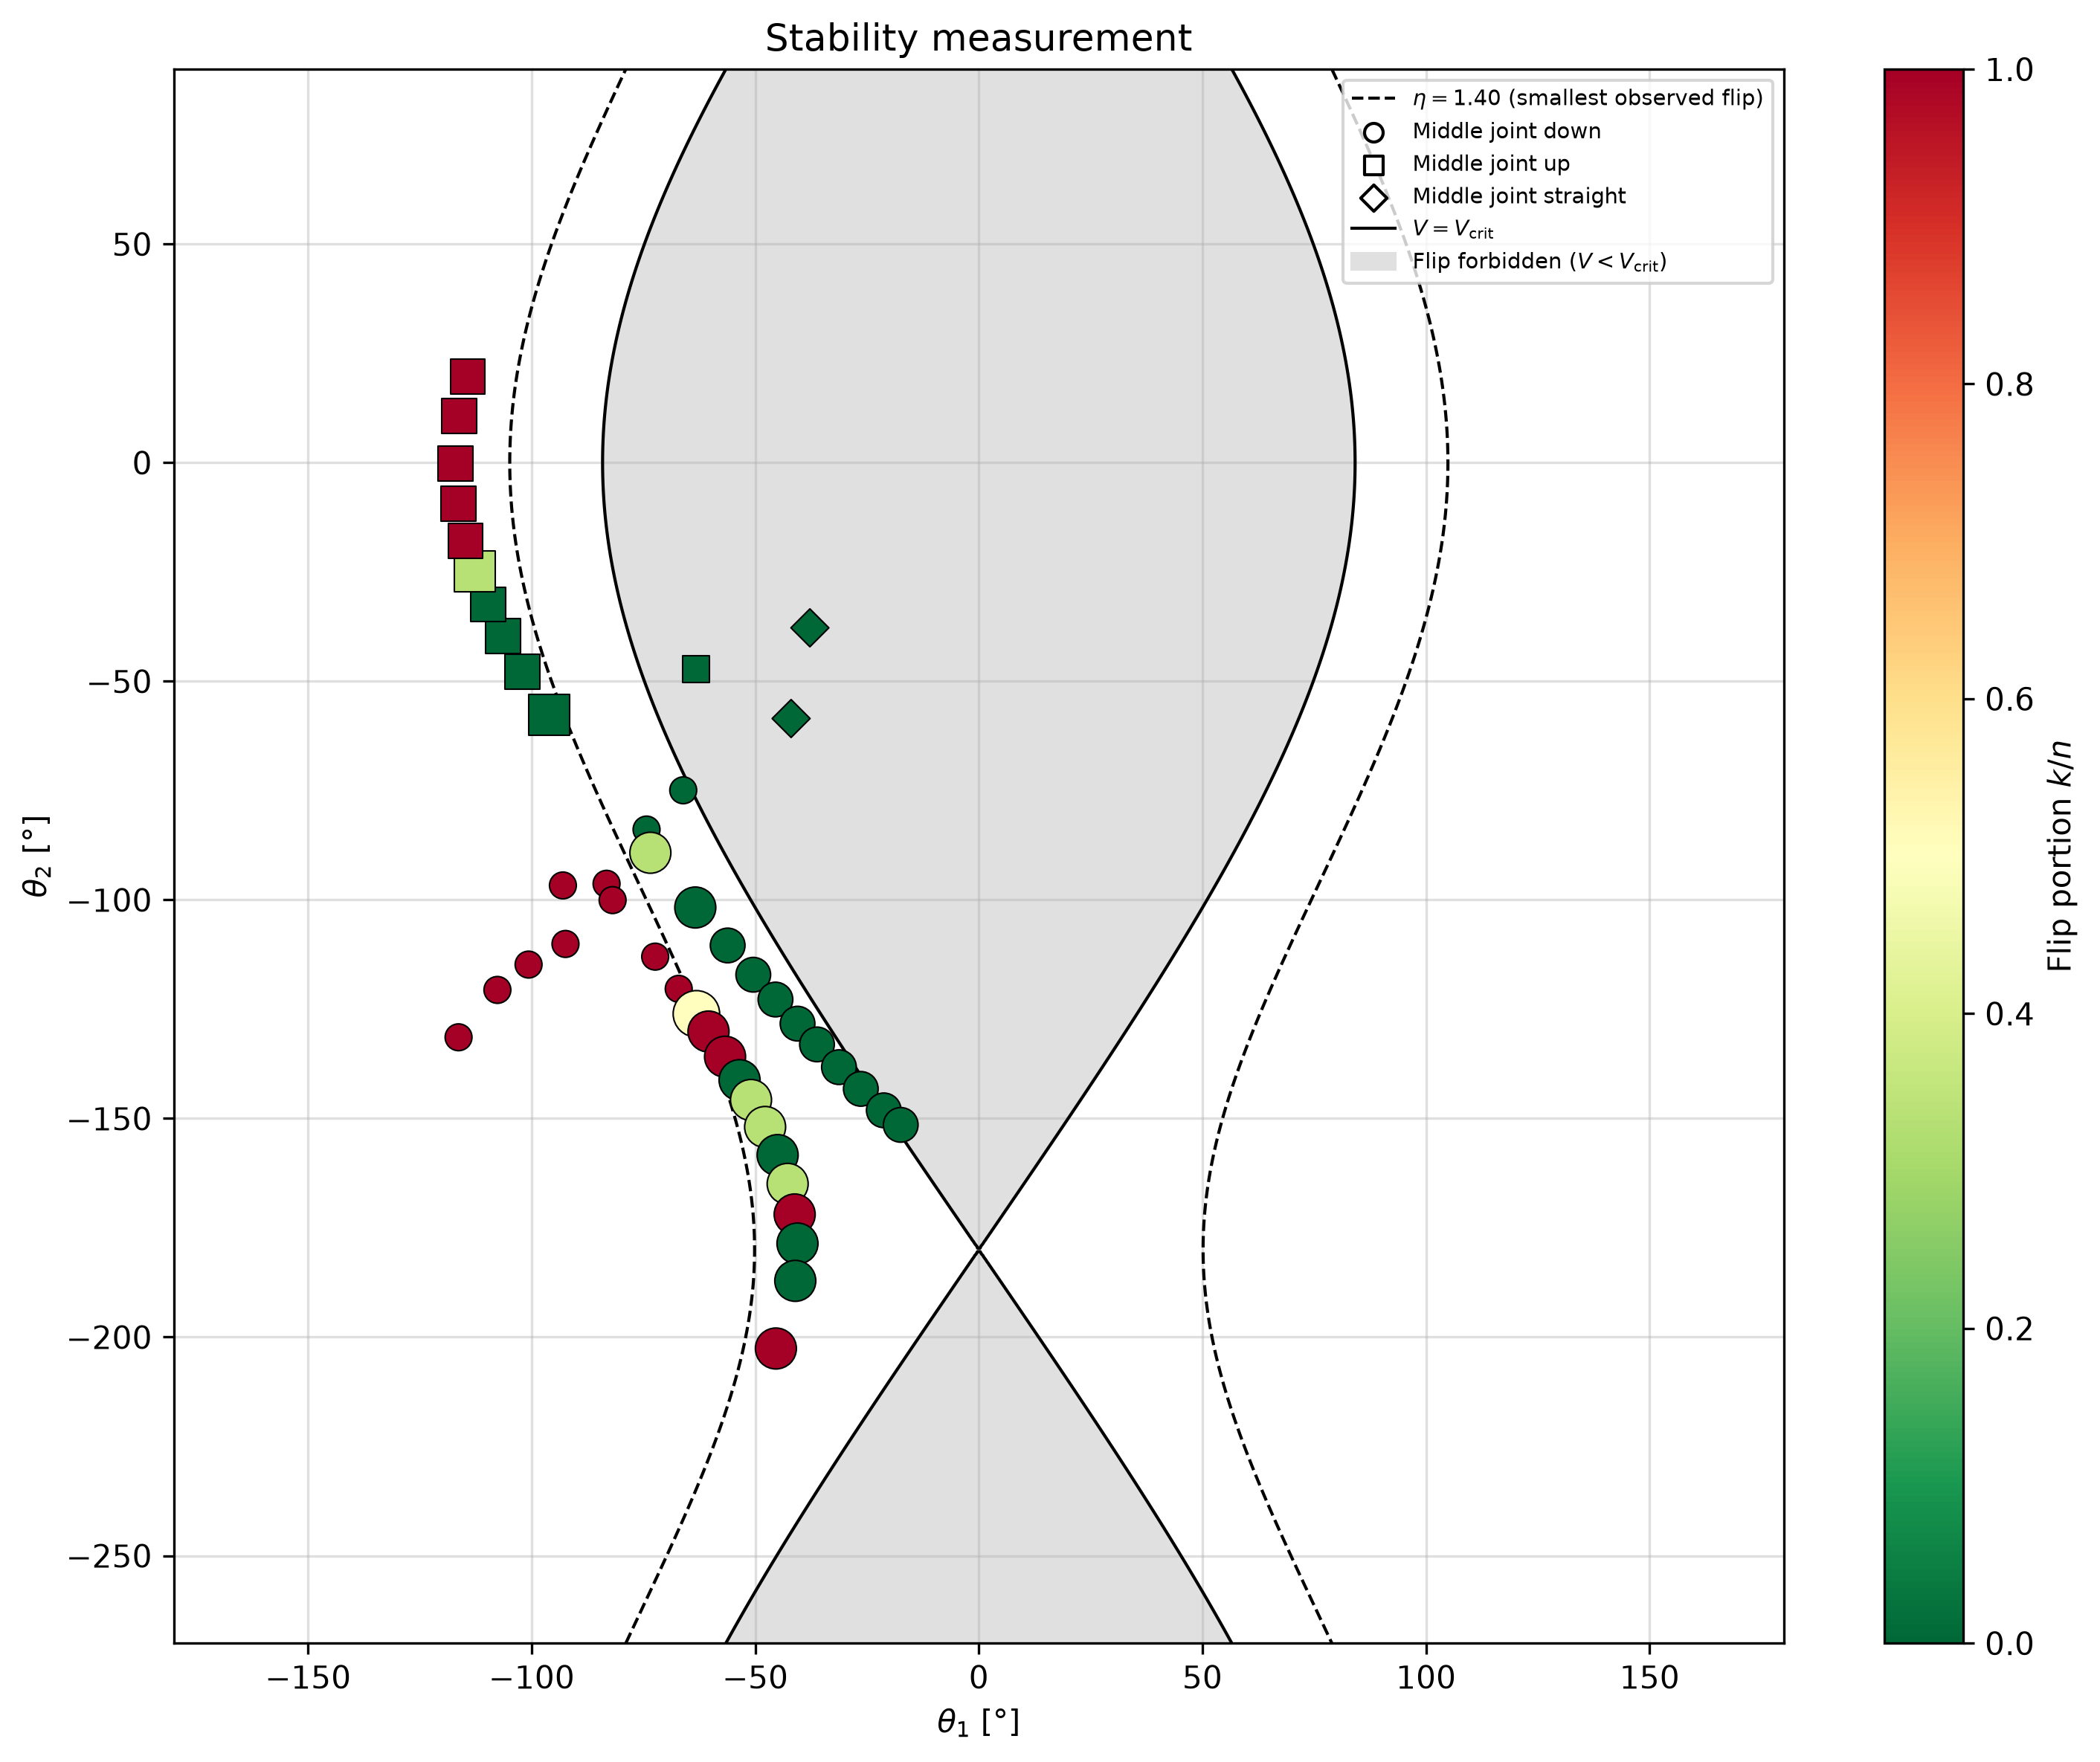

In [ ]:

x_lim = np.array([-180, 180])
y_lim = np.array([-270, 90])

fig, ax = plt.subplots(figsize=(10, 8), dpi=300)

# --- Hintergrund: Bereich, in dem ein Flip energetisch verboten ist ---
th1_grid, th2_grid = np.meshgrid(np.linspace(*x_lim, 600),
                                 np.linspace(*y_lim, 600))
V_grid = pot_energy(np.deg2rad(th1_grid), np.deg2rad(th2_grid))
ax.contourf(th1_grid, th2_grid, V_grid, levels=[V_grid.min(), V_crit], colors=["0.88"])
ax.contour(th1_grid, th2_grid, V_grid, levels=[V_crit], colors="black", linewidths=1, linestyles="-")

V_emp = V_min + eta_min_flip * (V_crit - V_min)   # eta zurück in eine Energie umrechnen
ax.contour(th1_grid, th2_grid, V_grid, levels=[V_emp],
           colors="black", linestyles="--", linewidths=1)
ax.plot([], [], color="black", ls="--", lw=1,
        label=rf"$\eta = {eta_min_flip:.2f}$ (smallest observed flip)")

# --- Messpunkte, je Gelenkstellung ein Marker ---
markers = {"down": "o", "up": "s", "straight": "D"}
for j, mk in markers.items():
    sub = groups[groups["joint"] == j]          # nur die Gruppen mit dieser Gelenkstellung
    sc = ax.scatter(sub["theta_1"], sub["theta_2"],
                    c=sub["p"], cmap="RdYlGn_r", vmin=0, vmax=1,   # Farbe = Flip-Anteil
                    s=25 + 50 * sub["n"],                         # Grösse = Anzahl Versuche
                    marker=mk, edgecolors="black", linewidths=0.5, zorder=3)
    ax.scatter([], [], marker=mk, facecolors="white", edgecolors="black", label=f"Middle joint {j}")

fig.colorbar(sc, ax=ax, label="Flip portion $k/n$")

# Legenden-Einträge für Linie und Fläche (haben sonst keinen Handle)
ax.plot([], [] , color="black", lw=1, label=r"$V = V_\mathrm{crit}$")
ax.fill_between([], [], color="0.88", label=r"Flip forbidden $(V < V_\text{crit})$")

ax.set_xlabel(r"$\theta_1$ [°]")
ax.set_ylabel(r"$\theta_2$ [°]")
ax.set_xlim(*x_lim)
ax.set_ylim(*y_lim)
ax.grid(alpha=0.4)
ax.set_title("Stability measurement")
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
#fig.savefig("final_plots/flip_map.pdf")
plt.show()